# Рекуррентные сети. Пропуски во временном ряду

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "07_rnn_missing"
OUT.mkdir(exist_ok=True, parents=True)

## Вариант 11. Пять способов обработки пропусков

Ряд из двух синусоид с шумом. Случайно удаляю 30% входных наблюдений, делю по времени 60/20/20. Сравниваю заполнение средним train, forward fill, интерполяцию внутри окна и два способа с признаком пропуска. Код — в sequences.py.

,method,MAE,RMSE,seconds,parameters
0,mean,0.18357,0.23219,0.67250,673
1,ffill,0.06938,0.08852,0.61544,673
2,linear,0.07124,0.09119,0.62148,673
3,mean_mask,0.12367,0.15598,0.63097,697
4,linear_mask,0.07471,0.09577,0.63922,697


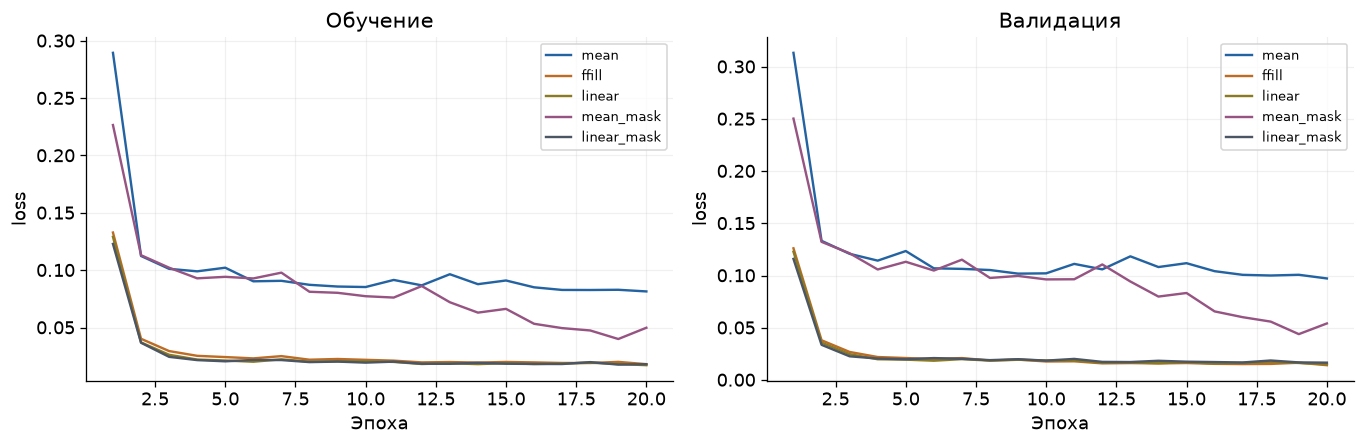

Выбор по validation: ffill test: {'MAE': 0.07418367266654968, 'RMSE': 0.09345655411266633}


,model,MAE,RMSE
0,RNN,0.07418,0.09346
1,last_observed_or_imputed,0.08554,0.10996
2,window_mean,0.45338,0.53534


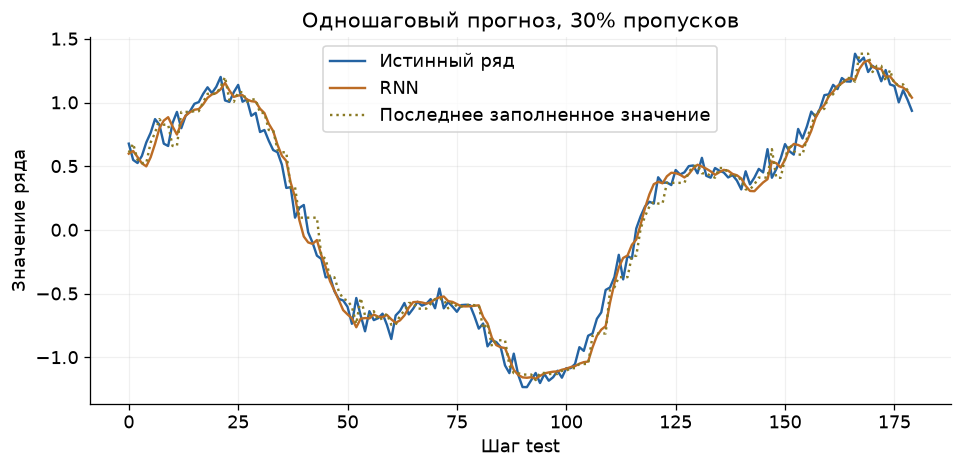

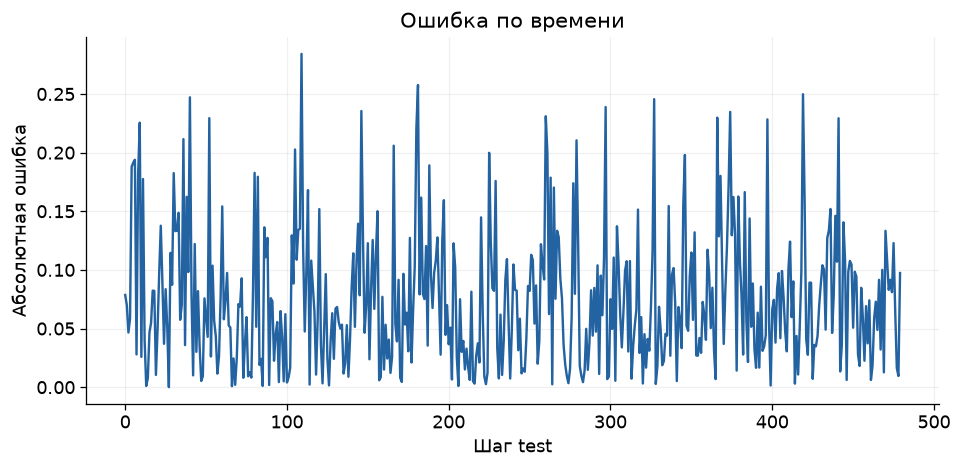

,test_step,truth,prediction,abs_error
0,366,-0.12494,0.10503,0.22997
1,260,-0.28167,-0.51285,0.23118
2,374,-0.56065,-0.32578,0.23488
3,146,0.63425,0.39862,0.23563
4,297,0.48873,0.24968,0.23904
5,327,0.79118,1.03693,0.24575
6,40,0.19610,-0.05121,0.24731
7,419,-0.51635,-0.26638,0.24997
8,181,0.73894,0.99677,0.25784
9,109,-0.47073,-0.75508,0.28435


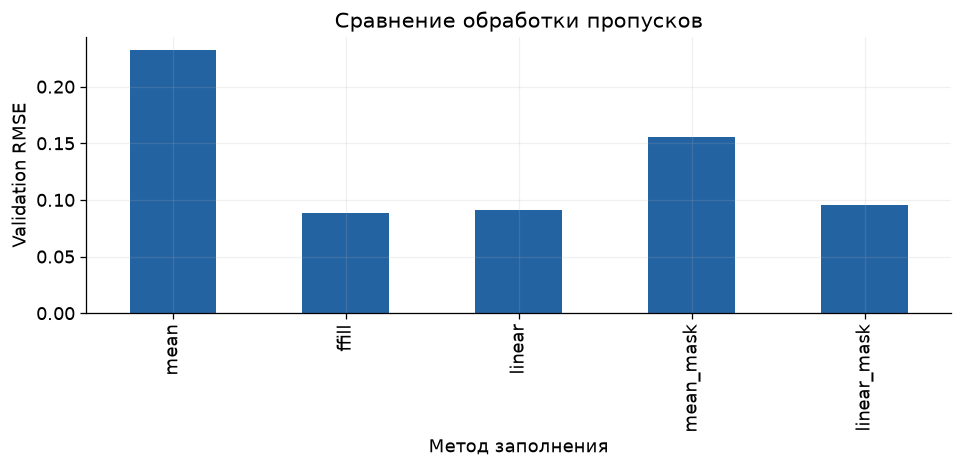

Лучший из заранее выбранных методов по validation: ffill. Интерполяция выполняется отдельно внутри каждого прошлого окна; значения после момента прогноза недоступны. Среднее и стандартное отклонение оценены по наблюдаемым train-значениям. Признак пропуска различает настоящее среднее и искусственное заполнение. Результат относится к случайным пропускам MCAR с долей 30%.

In [2]:
from sequences import missing_experiment, sequence_general

result = missing_experiment(OUT)

## Общая часть. Окна, hidden size, режимы и горизонты

Меняю длину окна и hidden size, сравниваю many-to-one/many-to-many, рекурсивный прогноз и NARX-подобную модель. Входное окно содержит только прошлые наблюдения.

,window,hidden,MAE,RMSE,parameters
0,10,24,0.07718,0.09757,673
1,30,24,0.07472,0.09548,673
2,60,24,0.07536,0.09590,673
3,30,8,0.08888,0.11287,97
4,30,48,0.07078,0.09031,2497


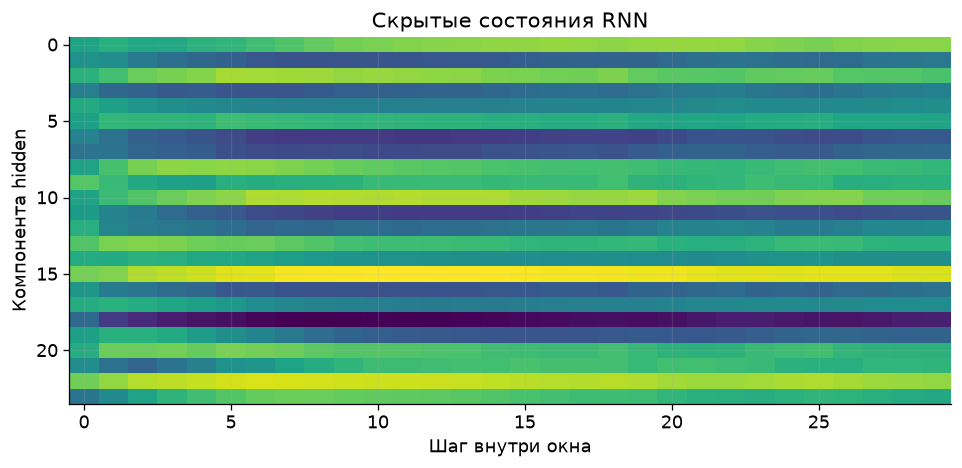

,horizon,RMSE
0,1,0.10483
1,5,0.18830
2,10,0.32833
3,20,0.63669


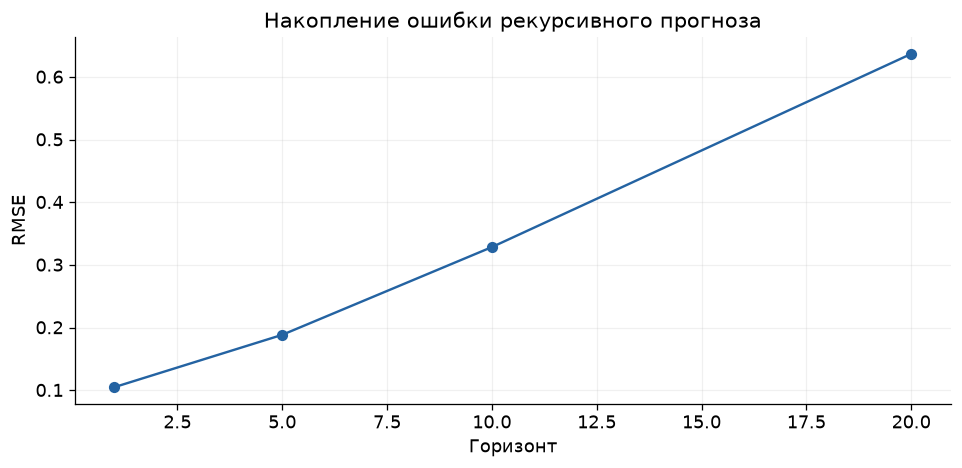

NARX-like open-loop test RMSE: 0.08164302760616114
NARX-like closed-loop first 100 RMSE: 0.8897555943093743
many-to-one: torch.Size([1, 1]) many-to-many: torch.Size([1, 30, 1])
Toy many-to-many MSE: 0.00460291700437665


В RNN контекст хранится в скрытом состоянии, в NARX-подобной модели задержанные входы и выходы подаются явно. Open-loop использует наблюдаемые выходы, closed-loop — собственные прогнозы. На длинном горизонте ошибки накапливаются.

In [3]:
sequence_general(result, OUT)

## Вывод по гипотезе

Проверяю, помогает ли учёт локальной динамики и признака пропуска по сравнению с заполнением константой.

In [4]:
note(
    "Выбор метода выполнен по validation RMSE. В таблицах сохранены метрики baseline и RNN, ошибка по времени и десять наиболее неудачных прогнозов. Интерполяция внутри прошлого окна допустима, а интерполяция через будущий момент прогноза создала бы утечку. При длительных непоследовательных пропусках результат может отличаться от случайного удаления 30% значений."
)

Выбор метода выполнен по validation RMSE. В таблицах сохранены метрики baseline и RNN, ошибка по времени и десять наиболее неудачных прогнозов. Интерполяция внутри прошлого окна допустима, а интерполяция через будущий момент прогноза создала бы утечку. При длительных непоследовательных пропусках результат может отличаться от случайного удаления 30% значений.

## Ответы на контрольные вопросы

1. h_t содержит обученное сжатое представление доступного прошлого; оно не обязано хранить всю последовательность.

2. Общие по времени веса задают одно правило перехода состояния, уменьшают число параметров и допускают разные длины.

3. BPTT применяет backpropagation к развёрнутому во времени вычислительному графу.

4. Случайное разбиение может смешать почти одинаковые перекрывающиеся окна и дать доступ к будущим режимам.

5. NARX явно использует задержанные выходы и внешние входы, позволяя строить нелинейный авторегрессионный прогноз.